# TP2 — Analyse des accidents de la route avec PySpark

## 1. Introduction

Dans ce TP, je vais reproduire une étude sur les accidents de la route en Australie-Méridionale, à partir de données couvrant la période 2012 à 2019.

L'objectif est d'utiliser PySpark pour analyser ces données à travers trois approches : les RDD, les DataFrames et Spark SQL.

Je vais notamment étudier les informations concernant les accidents, les véhicules et les conducteurs impliqués. Je comparerai également les différentes approches de traitement et présenterai les résultats obtenus à l'aide de tableaux et de graphiques.

**Étude de référence :** Rakesh Nain, *Big Data Analysis of Road Crash Data using PySpark with PySpark Tutorial*, Medium, 2021.
[Big Data Analysis of Road Crash Data using PySpark](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588?utm_source=chatgpt.com)

## 2. Installation et configuration de PySpark

In [42]:
# Installation de Java 17
!apt-get update -qq
!apt-get install -y -qq openjdk-17-jdk-headless

# Installation de PySpark
%pip install -q pyspark==3.5.8

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [43]:
import os
import sys

JAVA_HOME = "/usr/lib/jvm/java-17-openjdk-amd64"

os.environ["JAVA_HOME"] = JAVA_HOME
os.environ["PATH"] = JAVA_HOME + "/bin:" + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

from pyspark.sql import SparkSession
import pyspark.sql.functions as F

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("RoadCrashAnalysis")
    .config("spark.driver.host", "localhost")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.memory", "2g")
    .getOrCreate()
)

sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Version Spark :", spark.version)
print("Cœurs disponibles :", sc.defaultParallelism)
print("Test Spark :", sc.parallelize(range(10)).sum())

Version Spark : 3.5.8
Cœurs disponibles : 2
Test Spark : 45


## 3. Chargement des données

### 3.1. Présentation des jeux de données

Pour cette étude, j'utilise les données d'accidents de la route d'Australie-Méridionale entre 2012 et 2019, disponibles sur le portail public du gouvernement australien.

Je récupère les fichiers CSV depuis le dépôt GitHub de Rakesh Nain, qui les a regroupés en deux dossiers :

- **crash_data** : contient les informations générales sur les accidents.
- **units_data** : contient les informations sur les véhicules et les personnes impliquées.

Je vais ensuite charger ces fichiers dans PySpark pour réaliser les analyses avec les RDD et les DataFrames.

Source : https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial

In [44]:
from pathlib import Path
import subprocess

url = (
    "https://github.com/RakeshNain/"
    "Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial.git"
)

dossier_projet = Path("/content/road_crash_source")

# Télécharger uniquement si le dossier n'existe pas
if not dossier_projet.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", url, str(dossier_projet)],
        check=True
    )

# Localiser les CSV
crash_files = sorted((dossier_projet / "crash_data").glob("*.csv"))
units_files = sorted((dossier_projet / "units_data").glob("*.csv"))

assert crash_files, "Aucun fichier crash_data trouvé"
assert units_files, "Aucun fichier units_data trouvé"

print("Fichiers Crash :", len(crash_files))
print("Fichiers Units :", len(units_files))

print("\nFichiers Crash :")
for f in crash_files:
    print("-", f.name)

print("\nFichiers Units :")
for f in units_files:
    print("-", f.name)

Fichiers Crash : 8
Fichiers Units : 8

Fichiers Crash :
- 2012_DATA_SA_Crash.csv
- 2013_DATA_SA_Crash.csv
- 2014_DATA_SA_Crash.csv
- 2015_DATA_SA_Crash.csv
- 2016_DATA_SA_Crash.csv
- 2017_DATA_SA_Crash.csv
- 2018_DATA_SA_Crash.csv
- 2019_DATA_SA_Crash.csv

Fichiers Units :
- 2012_DATA_SA_Units.csv
- 2013_DATA_SA_Units.csv
- 2014_DATA_SA_Units.csv
- 2015_DATA_SA_Units.csv
- 2016_DATA_SA_Units.csv
- 2017_DATA_SA_Units.csv
- 2018_DATA_SA_Units.csv
- 2019_DATA_SA_Units.csv


In [45]:
import csv

for nom, fichier in [
    ("Crash", crash_files[0]),
    ("Units", units_files[0])
]:
    with open(fichier, encoding="utf-8-sig", newline="") as f:
        colonnes = next(csv.reader(f))

    print(f"\n{nom} — {fichier.name}")
    print("Nombre de colonnes :", len(colonnes))
    print("Colonnes :", colonnes)


Crash — 2012_DATA_SA_Crash.csv
Nombre de colonnes : 33
Colonnes : ['REPORT_ID', 'Stats Area', 'Suburb', 'Postcode', 'LGA Name', 'Total Units', 'Total Cas', 'Total Fats', 'Total SI', 'Total MI', 'Year', 'Month', 'Day', 'Time', 'Area Speed', 'Position Type', 'Horizontal Align', 'Vertical Align', 'Other Feat', 'Road Surface', 'Moisture Cond', 'Weather Cond', 'DayNight', 'Crash Type', 'Unit Resp', 'Entity Code', 'CSEF Severity', 'Traffic Ctrls', 'DUI Involved', 'Drugs Involved', 'ACCLOC_X', 'ACCLOC_Y', 'UNIQUE_LOC']

Units — 2012_DATA_SA_Units.csv
Nombre de colonnes : 18
Colonnes : ['REPORT_ID', 'Unit No', 'No Of Cas', 'Veh Reg State', 'Unit Type', 'Veh Year', 'Direction Of Travel', 'Sex', 'Age', 'Lic State', 'Licence Class', 'Licence Type', 'Towing', 'Unit Movement', 'Number Occupants', 'Postcode', 'Rollover', 'Fire']


## 4. Préparation et chargement des données

### 4.1. Vérification des schémas

In [46]:
import csv

def verifier_colonnes(fichiers, nom):
    entetes = []

    for fichier in fichiers:
        with open(fichier, encoding="utf-8-sig", newline="") as f:
            colonnes = next(csv.reader(f))
            entetes.append(colonnes)

    reference = entetes[0]

    for fichier, colonnes in zip(fichiers, entetes):
        identiques = colonnes == reference
        print(f"{nom} - {fichier.name} : "
              f"{len(colonnes)} colonnes | "
              f"Identiques : {identiques}")

    return all(cols == reference for cols in entetes)


crash_ok = verifier_colonnes(crash_files, "Crash")
units_ok = verifier_colonnes(units_files, "Units")

print("\nSchémas compatibles :", crash_ok and units_ok)

Crash - 2012_DATA_SA_Crash.csv : 33 colonnes | Identiques : True
Crash - 2013_DATA_SA_Crash.csv : 33 colonnes | Identiques : True
Crash - 2014_DATA_SA_Crash.csv : 33 colonnes | Identiques : True
Crash - 2015_DATA_SA_Crash.csv : 33 colonnes | Identiques : True
Crash - 2016_DATA_SA_Crash.csv : 33 colonnes | Identiques : True
Crash - 2017_DATA_SA_Crash.csv : 33 colonnes | Identiques : True
Crash - 2018_DATA_SA_Crash.csv : 33 colonnes | Identiques : True
Crash - 2019_DATA_SA_Crash.csv : 33 colonnes | Identiques : True
Units - 2012_DATA_SA_Units.csv : 18 colonnes | Identiques : True
Units - 2013_DATA_SA_Units.csv : 18 colonnes | Identiques : True
Units - 2014_DATA_SA_Units.csv : 18 colonnes | Identiques : True
Units - 2015_DATA_SA_Units.csv : 18 colonnes | Identiques : True
Units - 2016_DATA_SA_Units.csv : 18 colonnes | Identiques : True
Units - 2017_DATA_SA_Units.csv : 18 colonnes | Identiques : True
Units - 2018_DATA_SA_Units.csv : 18 colonnes | Identiques : True
Units - 2019_DATA_SA_Unit

### 4.2. Chargement des données avec PySpark

Après avoir récupéré les fichiers CSV, je les charge dans deux DataFrames Spark.

Je regroupe les huit fichiers de chaque catégorie afin de pouvoir travailler sur l'ensemble des données de 2012 à 2019.

J'utilise l'option `header=True` pour conserver les noms des colonnes et `inferSchema=True` pour permettre à Spark de détecter les types des données.

In [47]:
# Vérifier la compatibilité avant le chargement
assert crash_ok and units_ok, (
    "Les colonnes diffèrent entre certaines années."
)

# Chargement des données Crash
df_crash = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv([str(f) for f in crash_files])
)

# Chargement des données Units
df_units = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv([str(f) for f in units_files])
)

# Vérification du chargement
print("Nombre d'accidents :", df_crash.count())
print("Nombre de lignes Units :", df_units.count())

print("\nPartitions Crash :", df_crash.rdd.getNumPartitions())
print("Partitions Units :", df_units.rdd.getNumPartitions())

print("\nSchéma Crash :")
df_crash.printSchema()

print("\nSchéma Units :")
df_units.printSchema()

Nombre d'accidents : 127672
Nombre de lignes Units : 272591

Partitions Crash : 2
Partitions Units : 2

Schéma Crash :
root
 |-- REPORT_ID: string (nullable = true)
 |-- Stats Area: string (nullable = true)
 |-- Suburb: string (nullable = true)
 |-- Postcode: integer (nullable = true)
 |-- LGA Name: string (nullable = true)
 |-- Total Units: integer (nullable = true)
 |-- Total Cas: integer (nullable = true)
 |-- Total Fats: integer (nullable = true)
 |-- Total SI: integer (nullable = true)
 |-- Total MI: integer (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: string (nullable = true)
 |-- Day: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Area Speed: integer (nullable = true)
 |-- Position Type: string (nullable = true)
 |-- Horizontal Align: string (nullable = true)
 |-- Vertical Align: string (nullable = true)
 |-- Other Feat: string (nullable = true)
 |-- Road Surface: string (nullable = true)
 |-- Moisture Cond: string (nullable = true)
 |-- 

## 5. Analyse des données avec les RDD

### 5.1. Création des RDD

Dans cette première partie, j'utilise les RDD (*Resilient Distributed Datasets*) de PySpark.

Un RDD est une collection de données distribuée en plusieurs partitions, sur lesquelles Spark peut exécuter des opérations en parallèle.

Je convertis les DataFrames déjà chargés en RDD pour éviter de relire et de découper manuellement les fichiers CSV.

Je commence par vérifier le nombre d'enregistrements et le nombre de partitions de chaque RDD.

In [48]:
# Conversion des DataFrames en RDD
crash_rdd = df_crash.rdd
units_rdd = df_units.rdd

print("Crash :")
print("Enregistrements :", crash_rdd.count())
print("Partitions :", crash_rdd.getNumPartitions())

print("\nUnits :")
print("Enregistrements :", units_rdd.count())
print("Partitions :", units_rdd.getNumPartitions())

# Exemple d'enregistrement
print("\nPremier enregistrement Units :")
print(units_rdd.first())

Crash :
Enregistrements : 127672
Partitions : 2

Units :
Enregistrements : 272591
Partitions : 2

Premier enregistrement Units :
Row(REPORT_ID='2012-1-21/08/2019', Unit No=1, No Of Cas=0, Veh Reg State=None, Unit Type='Pedal Cycle', Veh Year=None, Direction Of Travel='South West', Sex='Male', Age='035', Lic State=None, Licence Class=None, Licence Type=None, Towing=None, Unit Movement='Straight Ahead', Number Occupants='001', Postcode='5074', Rollover=None, Fire=None)


### 5.2. Partitionnement des données

Je vais maintenant répartir les données Units en deux partitions en fonction de l'État d'immatriculation du véhicule.

La première partition contiendra les véhicules immatriculés en Australie-Méridionale (`SA`), tandis que la seconde regroupera les autres véhicules.

Pour cela, j'utilise `map()` pour créer des paires clé-valeur à partir de la colonne `Veh Reg State`, puis `partitionBy()` pour définir la répartition des données.

Je pourrai ensuite vérifier le nombre d'enregistrements présents dans chaque partition.

In [49]:
# Création de paires (État d'immatriculation, enregistrement)
units_state_rdd = units_rdd.map(
    lambda row: (row["Veh Reg State"], row)
)

# Fonction de partitionnement
def partition_etat(etat):
    if etat == "SA":
        return 0
    return 1

# Création des deux partitions
units_partitioned = units_state_rdd.partitionBy(
    2, partition_etat
)

# Comptage des éléments dans chaque partition
repartition = units_partitioned.mapPartitionsWithIndex(
    lambda index, lignes: [
        (index, sum(1 for _ in lignes))
    ]
).collect()

print("Nombre de partitions :",
      units_partitioned.getNumPartitions())

for index, nombre in sorted(repartition):
    groupe = "SA" if index == 0 else "Autres États"
    print(f"Partition {index} ({groupe}) : {nombre} lignes")

# Vérification de la conservation des enregistrements
assert sum(n for _, n in repartition) == df_units.count()
print("\nPartitionnement correct : OK")

Nombre de partitions : 2
Partition 0 (SA) : 218366 lignes
Partition 1 (Autres États) : 54225 lignes

Partitionnement correct : OK


### 5.3. Amélioration du partitionnement : gestion des valeurs manquantes

Le partitionnement précédent fonctionne correctement, mais j'ai remarqué une limite dans la façon dont les enregistrements sont répartis.

Avec ma fonction, toutes les valeurs différentes de `SA` sont envoyées dans la deuxième partition, y compris celles pour lesquelles l'État d'immatriculation n'est pas renseigné.

Cela peut fausser l'interprétation de cette partition si je considère qu'elle contient uniquement des véhicules immatriculés dans d'autres États.

Avant de modifier le partitionnement, je vais examiner les différentes valeurs présentes dans la colonne `Veh Reg State` et leur fréquence.

In [50]:
from pyspark.sql import functions as F

# Répartition des états d'immatriculation
repartition_etats = (
    df_units
    .groupBy("Veh Reg State")
    .count()
    .orderBy(F.desc("count"))
)

repartition_etats.show(50, truncate=False)

# Nombre de valeurs nulles
nb_null = df_units.filter(
    F.col("Veh Reg State").isNull()
).count()

print("Valeurs nulles :", nb_null)
print("Total des enregistrements :", df_units.count())

+-------------+------+
|Veh Reg State|count |
+-------------+------+
|SA           |218366|
|NULL         |38778 |
|UNKNOWN      |8685  |
|VIC          |3301  |
|NSW          |1130  |
|QLD          |965   |
|WA           |713   |
|NT           |272   |
|FEDERAL      |194   |
|TAS          |104   |
|ACT          |77    |
|O/S          |6     |
+-------------+------+

Valeurs nulles : 38778
Total des enregistrements : 272591


### 5.4. Amélioration du partitionnement

En analysant la colonne `Veh Reg State`, j'ai remarqué que certaines valeurs ne correspondent pas à un État d'immatriculation connu.

Sur les 272 591 enregistrements, 38 778 possèdent une valeur NULL et 8 685 contiennent la valeur UNKNOWN.

Avec le partitionnement initial, ces enregistrements étaient regroupés avec les véhicules immatriculés en dehors de l'Australie-Méridionale. La deuxième partition contenait donc des informations de nature différente.

J'ai décidé de créer trois groupes : les immatriculations SA, les autres immatriculations renseignées et les informations inconnues.

Cette modification me permet de mieux distinguer les données manquantes des autres catégories, sans supprimer d'enregistrements.

L'objectif de cette amélioration est surtout de rendre l'analyse plus précise, et pas nécessairement d'accélérer le traitement.

In [51]:
# Amélioration : partitionnement en 3 groupes

def classer_immatriculation(etat):
    if etat is None:
        return "Inconnu"

    etat = str(etat).strip().upper()

    if etat in ("", "UNKNOWN"):
        return "Inconnu"

    if etat == "SA":
        return "SA"

    return "Autres renseignées"


# Affecter un numéro de partition à chaque groupe
def partition_groupe(groupe):
    partitions = {
        "SA": 0,
        "Autres renseignées": 1,
        "Inconnu": 2
    }
    return partitions[groupe]


# Création du nouveau RDD partitionné
units_partitioned_v2 = (
    units_rdd
    .map(lambda row: (
        classer_immatriculation(row["Veh Reg State"]),
        row
    ))
    .partitionBy(3, partition_groupe)
)


# Compter les enregistrements de chaque partition
resultats_partitions = dict(
    units_partitioned_v2.mapPartitionsWithIndex(
        lambda index, lignes: [
            (index, sum(1 for _ in lignes))
        ]
    ).collect()
)

noms = ["SA", "Autres renseignées", "Inconnu"]

for index in sorted(resultats_partitions):
    print(
        f"Partition {index} ({noms[index]}) : "
        f"{resultats_partitions[index]} lignes"
    )

# Vérifier qu'aucune ligne n'a été perdue
assert sum(resultats_partitions.values()) == df_units.count()

print("\nNombre total :", sum(resultats_partitions.values()))
print("Amélioration validée : OK")

Partition 0 (SA) : 218366 lignes
Partition 1 (Autres renseignées) : 6762 lignes
Partition 2 (Inconnu) : 47463 lignes

Nombre total : 272591
Amélioration validée : OK


### 5.5. Bilan de l'amélioration du partitionnement

Le nouveau partitionnement fonctionne correctement et conserve les 272 591 enregistrements.

J'obtiens 218 366 lignes pour les immatriculations SA, 6 762 pour les autres immatriculations renseignées et 47 463 pour les valeurs inconnues.

Dans la première version, les données manquantes étaient mélangées avec les autres immatriculations. Avec cette modification, je peux distinguer ces cas et éviter une mauvaise interprétation des résultats.

J'ai toutefois conservé le partitionnement original afin de pouvoir comparer les deux méthodes.

Cette amélioration concerne principalement la qualité de l'analyse. Elle ne cherche pas à équilibrer les partitions ni à réduire le temps de calcul.

### 5.6. Âge moyen selon le sexe

Je cherche maintenant à calculer l'âge moyen des personnes renseignées dans le jeu de données Units, en distinguant les hommes et les femmes.

La colonne `Age` étant de type texte, je dois commencer par nettoyer les valeurs avant d'effectuer mes calculs.

J'exclus les âges manquants, non numériques ou considérés comme non plausibles (en dehors de 1 à 110 ans).

J'utilise ensuite `reduceByKey()` pour calculer la somme des âges et le nombre de personnes par groupe. Cette approche permet d'effectuer une agrégation sans regrouper tous les âges dans des listes, contrairement à `groupByKey()` utilisé dans l'étude originale.

In [52]:
# Extraction et nettoyage du sexe et de l'âge
def extraire_sexe_age(row):

    sexe = row["Sex"]
    age = row["Age"]

    if sexe is None or age is None:
        return None

    sexe = str(sexe).strip()
    age = str(age).strip()

    if sexe not in ("Male", "Female"):
        return None

    if not age.isdigit():
        return None

    age = int(age)

    # Exclure les valeurs non plausibles
    if not (1 <= age <= 110):
        return None

    return (sexe, (age, 1))


# Préparation des données
rdd_sexe_age = (
    units_rdd
    .map(extraire_sexe_age)
    .filter(lambda x: x is not None)
)

# Calcul : somme des âges et nombre d'enregistrements
statistiques = rdd_sexe_age.reduceByKey(
    lambda a, b: (a[0] + b[0], a[1] + b[1])
)

# Affichage des moyennes
for sexe, (somme, nombre) in sorted(statistiques.collect()):
    moyenne = somme / nombre
    print(f"{sexe} : {moyenne:.2f} ans ({nombre} personnes)")

print("\nTotal des enregistrements retenus :",
      rdd_sexe_age.count())

Female : 40.08 ans (85602 personnes)
Male : 40.80 ans (131891 personnes)

Total des enregistrements retenus : 217493


### 5.7. Analyse des années des véhicules

Je cherche maintenant à retrouver les cinq enregistrements de véhicules ayant les années les plus anciennes et les cinq ayant les années les plus récentes.

J'utilise les colonnes `Veh Year`, `Veh Reg State` et `Unit Type` du jeu de données Units.

Je commence par retirer les années manquantes ou non numériques, puis je classe les véhicules selon leur année.

Pour cette analyse, j'utilise `takeOrdered(5)` plutôt que de trier l'ensemble du RDD et de récupérer tous les résultats avec `collect()`. Cela me permet de limiter les données renvoyées à Python aux cinq enregistrements recherchés.

In [53]:
# Extraction de l'année et des informations du véhicule
def extraire_annee_vehicule(row):
    annee = row["Veh Year"]

    if annee is None:
        return None

    annee = str(annee).strip()

    if not annee.isdigit():
        return None

    return (
        int(annee),
        (row["Veh Reg State"], row["Unit Type"])
    )


# Nettoyage des données
vehicules_rdd = (
    units_rdd
    .map(extraire_annee_vehicule)
    .filter(lambda x: x is not None)
)

# Recherche des cinq années les plus anciennes
anciens = vehicules_rdd.takeOrdered(
    5, key=lambda x: x[0]
)

# Recherche des cinq années les plus récentes
recents = vehicules_rdd.takeOrdered(
    5, key=lambda x: -x[0]
)

print("5 véhicules les plus anciens :")
for annee, (etat, type_vehicule) in anciens:
    print(annee, "|", etat, "|", type_vehicule)

print("\n5 véhicules les plus récents :")
for annee, (etat, type_vehicule) in recents:
    print(annee, "|", etat, "|", type_vehicule)

5 véhicules les plus anciens :
1900 | SA | Motor Cycle
1900 | SA | Motor Cycle
1900 | SA | Motor Cycle
1900 | VIC | Motor Cycle
1900 | SA | Motor Cycle

5 véhicules les plus récents :
2019 | SA | Station Wagon
2019 | SA | OMNIBUS
2019 | SA | Motor Cars - Sedan
2019 | SA | Station Wagon
2019 | SA | SEMI TRAILER


## 6. Analyse avec les DataFrames PySpark

### 6.1. Recherche des accidents à Adelaide

Après les RDD, je passe aux DataFrames PySpark pour réaliser les analyses suivantes.

Les DataFrames permettent de manipuler les données sous forme de tableaux avec des colonnes nommées. Ils facilitent notamment le filtrage, le tri et le regroupement des résultats.

Je réutilise les DataFrames `df_crash` et `df_units` chargés précédemment, sans avoir besoin de relire les fichiers CSV.

Pour ma première requête, je recherche les accidents survenus dans le quartier d'Adelaide et ayant causé plus de trois victimes (*casualties*).

J'utilise la colonne `Suburb` pour sélectionner Adelaide et `Total Cas` pour identifier les accidents concernés.

In [54]:
from pyspark.sql import functions as F

# Accidents à Adelaide avec plus de 3 victimes
accidents_adelaide = (
    df_crash
    .filter(
        (F.col("Suburb") == "ADELAIDE") &
        (F.col("Total Cas") > 3)
    )
    .orderBy(F.desc("Total Cas"), F.asc("REPORT_ID"))
)

# Affichage des résultats
accidents_adelaide.select(
    "REPORT_ID",
    "Suburb",
    "Year",
    "Total Cas",
    "Total Fats",
    "Crash Type"
).show(20, truncate=False)

print(
    "Nombre d'accidents trouvés :",
    accidents_adelaide.count()
)

+---------------------+--------+----+---------+----------+--------------+
|REPORT_ID            |Suburb  |Year|Total Cas|Total Fats|Crash Type    |
+---------------------+--------+----+---------+----------+--------------+
|2019-10404-8/07/2020 |ADELAIDE|2019|6        |0         |Right Turn    |
|2017-12182-15/08/2019|ADELAIDE|2017|5        |0         |Hit Pedestrian|
|2012-4842-21/08/2019 |ADELAIDE|2012|4        |0         |Rear End      |
|2012-5769-21/08/2019 |ADELAIDE|2012|4        |0         |Right Angle   |
|2017-1613-15/08/2019 |ADELAIDE|2017|4        |0         |Right Turn    |
|2018-601-17/01/2020  |ADELAIDE|2018|4        |0         |Hit Pedestrian|
+---------------------+--------+----+---------+----------+--------------+

Nombre d'accidents trouvés : 6


### 6.2. Amélioration du filtrage des quartiers

La première requête m'a permis de retrouver six accidents à Adelaide ayant causé plus de trois victimes.

J'ai cependant remarqué que mon filtre recherchait uniquement la valeur exacte `ADELAIDE`. Si le nom du quartier contenait des minuscules ou des espaces supplémentaires, certains accidents pourraient ne pas être pris en compte.

J'ai donc décidé d'améliorer ce filtrage en utilisant `upper()` et `trim()`.

Je vais comparer les résultats obtenus avec les deux méthodes pour vérifier si cette modification permet de retrouver des enregistrements supplémentaires.

In [55]:
from pyspark.sql import functions as F

# Filtrage amélioré
accidents_adelaide_v2 = df_crash.filter(
    (F.upper(F.trim(F.col("Suburb"))) == "ADELAIDE") &
    (F.col("Total Cas") > 3)
)

# Comparaison des deux versions
nb_original = accidents_adelaide.count()
nb_ameliore = accidents_adelaide_v2.count()

print("Version originale :", nb_original, "accidents")
print("Version améliorée :", nb_ameliore, "accidents")

# Rechercher les éventuels accidents supplémentaires
nouveaux = (
    accidents_adelaide_v2
    .select("REPORT_ID")
    .exceptAll(accidents_adelaide.select("REPORT_ID"))
)

print("Accidents supplémentaires :", nouveaux.count())

nouveaux.show(truncate=False)

assert nb_ameliore >= nb_original

Version originale : 6 accidents
Version améliorée : 6 accidents
Accidents supplémentaires : 0
+---------+
|REPORT_ID|
+---------+
+---------+



### 6.3. Bilan de l'amélioration du filtrage

Après avoir comparé les deux méthodes, j'obtiens le même résultat : six accidents à Adelaide ayant causé plus de trois victimes.

La version améliorée ne retrouve donc aucun accident supplémentaire dans les données actuelles.

Je conserve néanmoins cette modification, car elle permet de gérer les différences de majuscules et les espaces inutiles. Le filtrage sera ainsi moins sensible aux variations de saisie si les données évoluent.

### 6.4. Les dix accidents ayant causé le plus de victimes

Je cherche maintenant à identifier les dix accidents ayant causé le plus de victimes sur la période 2012 à 2019.

Pour cela, je trie le DataFrame Crash par ordre décroissant selon la colonne `Total Cas`, puis je récupère les dix premiers résultats.

Je conserve également le nombre de décès (`Total Fats`) et le type d'accident pour faciliter l'interprétation.

In [56]:
# Reproduction de l'analyse originale
top10_original = (
    df_crash
    .orderBy(F.desc("Total Cas"))
    .limit(10)
)

top10_original.select(
    "REPORT_ID",
    "Year",
    "Suburb",
    "Total Cas",
    "Total Fats",
    "Crash Type"
).show(10, truncate=False)

+---------------------+----+-------------+---------+----------+-----------+
|REPORT_ID            |Year|Suburb       |Total Cas|Total Fats|Crash Type |
+---------------------+----+-------------+---------+----------+-----------+
|2017-288-15/08/2019  |2017|PARA HILLS   |11       |0         |Right Angle|
|2016-3035-15/08/2019 |2016|HACKHAM      |9        |3         |Right Turn |
|2019-11734-8/07/2020 |2019|STURT        |9        |0         |Right Turn |
|2016-6630-15/08/2019 |2016|KANGAROO FLAT|9        |0         |Head On    |
|2014-9004-21/08/2019 |2014|APY          |9        |1         |Roll Over  |
|2014-14065-21/08/2019|2014|MODBURY NORTH|9        |0         |Rear End   |
|2015-2823-21/08/2019 |2015|HAWKER       |8        |0         |Roll Over  |
|2016-14407-15/08/2019|2016|STOCKWELL    |8        |1         |Head On    |
|2014-8966-21/08/2019 |2014|WINTINNA     |8        |2         |Roll Over  |
|2012-890-21/08/2019  |2012|KULPARA      |8        |1         |Head On    |
+-----------

### 6.5. Amélioration du classement

Le classement original repose uniquement sur le nombre de victimes.

En cas d'égalité, l'ordre des accidents peut varier. J'ai donc ajouté deux critères supplémentaires : le nombre de décès et l'identifiant de l'accident.

Le nombre de victimes reste mon critère principal. Le nombre de décès intervient uniquement pour départager les accidents ayant le même nombre de victimes.

J'ai également décidé de vérifier combien d'accidents possèdent le même nombre de victimes que le dixième du classement, afin de voir si la limite de dix résultats exclut certains ex æquo.

In [57]:
# Classement amélioré
top10_ameliore = (
    df_crash
    .orderBy(
        F.desc("Total Cas"),
        F.desc("Total Fats"),
        F.asc("REPORT_ID")
    )
    .limit(10)
)

top10_ameliore.select(
    "REPORT_ID",
    "Year",
    "Suburb",
    "Total Cas",
    "Total Fats",
    "Crash Type"
).show(10, truncate=False)

# Seuil correspondant au dixième accident
seuil = top10_ameliore.agg(
    F.min("Total Cas")
).first()[0]

# Nombre d'accidents avec au moins autant de victimes
nb_eligibles = df_crash.filter(
    F.col("Total Cas") >= seuil
).count()

print("Nombre de victimes du 10e accident :", seuil)
print("Accidents atteignant ce seuil :", nb_eligibles)
print("Accidents affichés :", top10_ameliore.count())

+---------------------+----+-------------+---------+----------+-----------+
|REPORT_ID            |Year|Suburb       |Total Cas|Total Fats|Crash Type |
+---------------------+----+-------------+---------+----------+-----------+
|2017-288-15/08/2019  |2017|PARA HILLS   |11       |0         |Right Angle|
|2016-3035-15/08/2019 |2016|HACKHAM      |9        |3         |Right Turn |
|2014-9004-21/08/2019 |2014|APY          |9        |1         |Roll Over  |
|2014-14065-21/08/2019|2014|MODBURY NORTH|9        |0         |Rear End   |
|2016-6630-15/08/2019 |2016|KANGAROO FLAT|9        |0         |Head On    |
|2019-11734-8/07/2020 |2019|STURT        |9        |0         |Right Turn |
|2016-7073-15/08/2019 |2016|MERRITON     |8        |4         |Head On    |
|2014-8966-21/08/2019 |2014|WINTINNA     |8        |2         |Roll Over  |
|2012-890-21/08/2019  |2012|KULPARA      |8        |1         |Head On    |
|2016-14407-15/08/2019|2016|STOCKWELL    |8        |1         |Head On    |
+-----------

### 6.6. Bilan et amélioration du classement des accidents

En comparant les deux classements, j'ai remarqué que les résultats n'étaient pas exactement identiques.

Le classement original affichait un accident à Hawker avec huit victimes et aucun décès, alors que ma deuxième version affichait à sa place un accident à Merriton avec huit victimes et quatre décès.

Cette différence vient de l'ajout du nombre de décès comme critère secondaire.

J'ai également constaté que onze accidents atteignaient le seuil de huit victimes, alors que mon classement était limité à dix résultats.

J'ai donc décidé de conserver tous les accidents ex æquo au seuil du dixième. Cela me permet de ne pas exclure un accident uniquement à cause de la limite d'affichage.

Je conserve le nombre de victimes comme critère principal et le nombre de décès comme critère secondaire. Cette dernière modification permet d'obtenir un classement plus complet, même s'il contient exceptionnellement plus de dix lignes.

In [58]:
# Amélioration : conserver tous les ex aequo du top 10

# 'seuil' a été calculé dans la cellule précédente
top_avec_ex_aequo = (
    df_crash
    .filter(F.col("Total Cas") >= seuil)
    .orderBy(
        F.desc("Total Cas"),
        F.desc("Total Fats"),
        F.asc("REPORT_ID")
    )
)

top_avec_ex_aequo.select(
    "REPORT_ID",
    "Year",
    "Suburb",
    "Total Cas",
    "Total Fats",
    "Crash Type"
).show(truncate=False)

print("Seuil du top 10 :", seuil, "victimes")
print("Accidents retenus :", top_avec_ex_aequo.count())

assert top_avec_ex_aequo.count() == nb_eligibles
print("Tous les ex aequo sont conservés : OK")

+---------------------+----+-------------+---------+----------+-----------+
|REPORT_ID            |Year|Suburb       |Total Cas|Total Fats|Crash Type |
+---------------------+----+-------------+---------+----------+-----------+
|2017-288-15/08/2019  |2017|PARA HILLS   |11       |0         |Right Angle|
|2016-3035-15/08/2019 |2016|HACKHAM      |9        |3         |Right Turn |
|2014-9004-21/08/2019 |2014|APY          |9        |1         |Roll Over  |
|2014-14065-21/08/2019|2014|MODBURY NORTH|9        |0         |Rear End   |
|2016-6630-15/08/2019 |2016|KANGAROO FLAT|9        |0         |Head On    |
|2019-11734-8/07/2020 |2019|STURT        |9        |0         |Right Turn |
|2016-7073-15/08/2019 |2016|MERRITON     |8        |4         |Head On    |
|2014-8966-21/08/2019 |2014|WINTINNA     |8        |2         |Roll Over  |
|2012-890-21/08/2019  |2012|KULPARA      |8        |1         |Head On    |
|2016-14407-15/08/2019|2016|STOCKWELL    |8        |1         |Head On    |
|2015-2823-2

### 6.7. Nombre de décès par type d'accident

Je cherche maintenant à identifier les types d'accidents ayant entraîné le plus grand nombre de décès entre 2012 et 2019.

Pour cela, je regroupe les données selon la colonne `Crash Type`, puis j'additionne les valeurs de `Total Fats`.

Je trie ensuite les résultats par ordre décroissant afin de retrouver les types d'accidents associés au plus grand nombre de décès.

In [59]:
# Total des décès par type d'accident
deces_par_type = (
    df_crash
    .groupBy("Crash Type")
    .agg(
        F.sum("Total Fats").alias("Total deces")
    )
    .orderBy(F.desc("Total deces"))
)

deces_par_type.show(20, truncate=False)

+--------------------------+-----------+
|Crash Type                |Total deces|
+--------------------------+-----------+
|Hit Fixed Object          |245        |
|Head On                   |136        |
|Hit Pedestrian            |109        |
|Roll Over                 |93         |
|Right Angle               |82         |
|Rear End                  |33         |
|Side Swipe                |30         |
|Right Turn                |26         |
|Hit Parked Vehicle        |10         |
|Hit Animal                |7          |
|Other                     |5          |
|Left Road - Out of Control|3          |
|Hit Object on Road        |2          |
+--------------------------+-----------+



### 6.8. Amélioration : prise en compte de la fréquence des accidents

Le nombre total de décès permet d'identifier les catégories ayant entraîné le plus de morts, mais il ne tient pas compte du nombre d'accidents dans chaque catégorie.

J'ai donc décidé de compléter l'analyse avec le nombre total d'accidents et la proportion de ceux ayant provoqué au moins un décès.

Je calcule cette proportion en divisant le nombre d'accidents mortels par le nombre d'accidents pour lesquels le nombre de décès est renseigné.

Cela me permettra de comparer deux indicateurs différents : le nombre total de décès et la proportion d'accidents mortels.

Je vérifierai également les valeurs manquantes pour éviter de considérer une information absente comme un accident sans décès.

In [60]:
# Statistiques complémentaires par type d'accident
statistiques_types = (
    df_crash
    .filter(F.col("Crash Type").isNotNull())
    .groupBy("Crash Type")
    .agg(
        F.count("*").alias("Nombre accidents"),

        F.count("Total Fats").alias("Deces renseignes"),

        F.sum("Total Fats").alias("Total deces"),

        F.sum(
            F.when(F.col("Total Fats") > 0, 1)
             .otherwise(0)
        ).alias("Accidents mortels")
    )
    .withColumn(
        "Pourcentage accidents mortels",
        F.round(
            F.col("Accidents mortels") * 100 /
            F.col("Deces renseignes"),
            2
        )
    )
)

print("Classement par nombre total de décès :")

statistiques_types.orderBy(
    F.desc("Total deces")
).show(20, truncate=False)

print("\nClassement par proportion d'accidents mortels :")

statistiques_types.orderBy(
    F.desc("Pourcentage accidents mortels")
).show(20, truncate=False)

Classement par nombre total de décès :
+--------------------------+----------------+----------------+-----------+-----------------+-----------------------------+
|Crash Type                |Nombre accidents|Deces renseignes|Total deces|Accidents mortels|Pourcentage accidents mortels|
+--------------------------+----------------+----------------+-----------+-----------------+-----------------------------+
|Hit Fixed Object          |19365           |19365           |245        |233              |1.2                          |
|Head On                   |2086            |2086            |136        |112              |5.37                         |
|Hit Pedestrian            |2848            |2848            |109        |109              |3.83                         |
|Roll Over                 |5304            |5304            |93         |89               |1.68                         |
|Right Angle               |24236           |24236           |82         |70               |0.29    

### 6.9. Bilan de l'analyse par type d'accident

En comparant les deux classements, je constate que les résultats sont différents selon l'indicateur utilisé.

Les collisions contre un obstacle fixe représentent le plus grand nombre de décès, avec 245 morts. En revanche, les collisions frontales présentent la plus forte proportion d'accidents mortels, avec 5,37 %.

Les collisions par l'arrière sont très fréquentes, mais leur proportion d'accidents mortels est relativement faible, à 0,09 %.

Cette amélioration m'a permis de comprendre qu'il ne suffit pas de comparer les nombres de décès pour interpréter la gravité des différentes catégories d'accidents.

Je dois également tenir compte du nombre d'accidents enregistrés dans chaque catégorie. Les proportions calculées décrivent les accidents présents dans le jeu de données, mais ne permettent pas à elles seules de mesurer le risque d'accident pour les usagers.

### 6.10. Analyse des accidents impliquant des conducteurs sans permis

Pour cette analyse, je cherche à connaître le nombre de victimes par quartier dans les accidents impliquant au moins un conducteur sans permis.

Les informations sur les accidents se trouvent dans le DataFrame Crash, tandis que les informations sur les permis sont présentes dans Units.

Je réalise donc une jointure entre les deux DataFrames avec la colonne commune `REPORT_ID`.

Je filtre ensuite la colonne `Licence Type` sur la valeur `Unlicenced`, qui est celle utilisée dans le jeu de données, puis je regroupe les résultats par quartier.

In [61]:
# Jointure entre les accidents et les unités impliquées
complete_df = df_crash.alias("c").join(
    df_units.alias("u"),
    F.col("c.REPORT_ID") == F.col("u.REPORT_ID"),
    "inner"
)

# Sélection des unités associées à un permis "Unlicenced"
accidents_sans_permis = complete_df.filter(
    F.col("u.Licence Type") == "Unlicenced"
)

# Nombre de victimes par quartier
victimes_sans_permis_original = (
    accidents_sans_permis
    .groupBy(F.col("c.Suburb").alias("Suburb"))
    .agg(
        F.sum(F.col("c.Total Cas")).alias("Total victimes")
    )
    .orderBy(F.desc("Total victimes"))
)

victimes_sans_permis_original.show(20, truncate=False)

+---------------+--------------+
|Suburb         |Total victimes|
+---------------+--------------+
|ADELAIDE       |43            |
|SALISBURY      |30            |
|PROSPECT       |27            |
|INGLE FARM     |22            |
|SALISBURY EAST |20            |
|MORPHETT VALE  |20            |
|MURRAY BRIDGE  |19            |
|DRY CREEK      |19            |
|NORTH ADELAIDE |17            |
|MAWSON LAKES   |17            |
|ENFIELD        |16            |
|GEPPS CROSS    |15            |
|REGENCY PARK   |15            |
|SALISBURY DOWNS|15            |
|PARA HILLS WEST|14            |
|ELIZABETH PARK |14            |
|SEATON         |14            |
|BEDFORD PARK   |13            |
|DAVOREN PARK   |13            |
|MOUNT GAMBIER  |13            |
+---------------+--------------+
only showing top 20 rows



In [62]:
# Vérifier si un même accident possède plusieurs
# unités associées à la catégorie "Unlicenced"

units_sans_permis = df_units.filter(
    F.col("Licence Type") == "Unlicenced"
)

doublons_accidents = (
    units_sans_permis
    .groupBy("REPORT_ID")
    .count()
    .filter(F.col("count") > 1)
)

print("Unités sans permis :", units_sans_permis.count())

print(
    "Accidents ayant plusieurs unités sans permis :",
    doublons_accidents.count()
)

doublons_accidents.orderBy(
    F.desc("count")
).show(10, truncate=False)

Unités sans permis : 3926
Accidents ayant plusieurs unités sans permis : 39
+---------------------+-----+
|REPORT_ID            |count|
+---------------------+-----+
|2012-17008-21/08/2019|2    |
|2016-8524-15/08/2019 |2    |
|2012-4900-21/08/2019 |2    |
|2014-3590-21/08/2019 |2    |
|2016-15199-15/08/2019|2    |
|2016-10310-15/08/2019|2    |
|2012-18870-21/08/2019|2    |
|2014-13751-21/08/2019|2    |
|2012-15262-21/08/2019|2    |
|2013-8320-21/08/2019 |2    |
+---------------------+-----+
only showing top 10 rows



### 6.11. Amélioration : éviter le double comptage des victimes

En vérifiant les résultats de la jointure, j'ai remarqué que 39 accidents possédaient plusieurs enregistrements associés à la catégorie `Unlicenced`.

Cela pose un problème pour le calcul des victimes. Lorsqu'un accident apparaît plusieurs fois après la jointure, son nombre de victimes est également répété.

J'ai donc décidé d'utiliser une jointure `left_semi` afin de sélectionner les accidents qui possèdent au moins une unité sans permis, sans multiplier leurs enregistrements.

Je vais comparer le résultat de cette nouvelle approche avec celui de la requête originale pour mesurer l'impact des doublons.

In [63]:
# Récupérer les identifiants des accidents concernés
ids_sans_permis = (
    df_units
    .filter(F.col("Licence Type") == "Unlicenced")
    .select("REPORT_ID")
    .distinct()
)

# Conserver chaque accident une seule fois
accidents_uniques = df_crash.join(
    ids_sans_permis,
    on="REPORT_ID",
    how="left_semi"
)

# Recalculer les victimes par quartier
victimes_corrigees = (
    accidents_uniques
    .groupBy("Suburb")
    .agg(
        F.sum("Total Cas").alias("Victimes corrigees")
    )
)

print("Classement corrigé :")

victimes_corrigees.orderBy(
    F.desc("Victimes corrigees")
).show(20, truncate=False)

Classement corrigé :
+---------------+------------------+
|Suburb         |Victimes corrigees|
+---------------+------------------+
|ADELAIDE       |42                |
|SALISBURY      |30                |
|PROSPECT       |27                |
|INGLE FARM     |22                |
|MORPHETT VALE  |20                |
|SALISBURY EAST |19                |
|MURRAY BRIDGE  |19                |
|DRY CREEK      |19                |
|NORTH ADELAIDE |17                |
|MAWSON LAKES   |17                |
|ENFIELD        |16                |
|SALISBURY DOWNS|15                |
|GEPPS CROSS    |15                |
|REGENCY PARK   |15                |
|PARA HILLS WEST|14                |
|ELIZABETH PARK |14                |
|SEATON         |14                |
|BEDFORD PARK   |13                |
|DAVOREN PARK   |13                |
|MOUNT GAMBIER  |13                |
+---------------+------------------+
only showing top 20 rows



In [64]:
# Préparation des deux résultats
ancien = (
    victimes_sans_permis_original
    .withColumnRenamed("Total victimes", "Avant")
    .fillna({"Suburb": "NON RENSEIGNE"})
)

nouveau = (
    victimes_corrigees
    .withColumnRenamed("Victimes corrigees", "Apres")
    .fillna({"Suburb": "NON RENSEIGNE"})
)

# Comparaison avant/après par quartier
comparaison_victimes = (
    ancien
    .join(nouveau, on="Suburb", how="full")
    .fillna(0, subset=["Avant", "Apres"])
    .withColumn(
        "Ecart",
        F.col("Avant") - F.col("Apres")
    )
    .orderBy(F.desc("Ecart"), F.desc("Avant"))
)

print("Quartiers avec les plus grands écarts :")
comparaison_victimes.show(20, truncate=False)

# Comparaison des totaux
totaux = comparaison_victimes.agg(
    F.sum("Avant").alias("Total avant"),
    F.sum("Apres").alias("Total apres"),
    F.sum("Ecart").alias("Surcomptage")
).first()

print("\nTotal avant :", totaux["Total avant"])
print("Total après :", totaux["Total apres"])
print("Surcomptage :", totaux["Surcomptage"])

# Vérifier que le comptage corrigé n'augmente pas
assert totaux["Surcomptage"] >= 0
print("Vérification : OK")

Quartiers avec les plus grands écarts :
+------------------+-----+-----+-----+
|Suburb            |Avant|Apres|Ecart|
+------------------+-----+-----+-----+
|ONKAPARINGA HILLS |8    |6    |2    |
|BAUDIN BEACH      |4    |2    |2    |
|FITZROY           |4    |2    |2    |
|ADELAIDE          |43   |42   |1    |
|SALISBURY EAST    |20   |19   |1    |
|SALISBURY NORTH   |11   |10   |1    |
|EDWARDSTOWN       |8    |7    |1    |
|MELROSE PARK      |8    |7    |1    |
|TORRENS PARK      |7    |6    |1    |
|FINDON            |6    |5    |1    |
|FERRYDEN PARK     |5    |4    |1    |
|O'HALLORAN HILL   |5    |4    |1    |
|SEFTON PARK       |4    |3    |1    |
|WILMINGTON        |4    |3    |1    |
|GLOBE DERBY PARK  |3    |2    |1    |
|COMMISSARIAT POINT|2    |1    |1    |
|SALISBURY         |30   |30   |0    |
|PROSPECT          |27   |27   |0    |
|INGLE FARM        |22   |22   |0    |
|MORPHETT VALE     |20   |20   |0    |
+------------------+-----+-----+-----+
only showing top 20 rows

### 6.12. Bilan de la correction de la jointure

La comparaison des deux méthodes montre que la jointure originale entraîne un double comptage de certaines victimes.

J'obtiens un total de 2 072 occurrences de victimes avant correction, contre 2 053 après correction, soit un écart de 19.

Certains quartiers sont davantage concernés, notamment Onkaparinga Hills, Baudin Beach et Fitzroy, avec deux occurrences comptées en trop chacun. À Adelaide, le total passe de 43 à 42.

Cette différence vient du fait qu'un même accident peut être associé à plusieurs unités classées `Unlicenced`. Avec une jointure classique, les informations de l'accident sont répétées pour chaque unité correspondante.

En utilisant une jointure `left_semi`, je conserve uniquement les accidents concernés, sans multiplier leur nombre de victimes.

Cette amélioration est importante, car elle corrige les résultats statistiques et pas seulement la présentation du code. Elle montre également qu'il faut faire attention aux relations entre les tables lorsqu'on réalise des agrégations après une jointure.

## 7. Comparaison entre RDD, DataFrames et Spark SQL

### 7.1. Analyse des accidents à Adelaide avec les DataFrames

Dans cette partie, je vais reproduire une même requête avec trois approches PySpark afin de comparer leur fonctionnement et leurs résultats.

Je commence par rechercher les accidents d'Adelaide en affichant les informations sur les unités impliquées.

J'apporte également une amélioration au code original en utilisant les fonctions natives de Spark pour construire la période de l'accident, plutôt qu'une fonction Python personnalisée.

Je prends aussi en compte le fait que le jour exact de l'accident n'est pas fourni dans les données. Je conserve donc l'année, le mois et le jour de la semaine sans présenter cette information comme une date précise.

In [65]:
from pyspark.sql import functions as F

# Jointure entre Crash et Units
adelaide_df = (
    df_crash.alias("c")
    .join(df_units.alias("u"), on="REPORT_ID", how="inner")
    .filter(
        F.upper(F.trim(F.col("c.Suburb"))) == "ADELAIDE"
    )
    .select(
        F.col("REPORT_ID"),
        F.col("u.Unit No").alias("Numero unite"),
        F.concat_ws(
            "-",
            F.col("c.Year").cast("string"),
            F.col("c.Month"),
            F.col("c.Day")
        ).alias("Annee-Mois-JourSemaine"),
        F.col("c.Time").alias("Heure"),
        F.col("c.Total Cas").alias("Victimes accident"),
        F.col("u.Sex").alias("Sexe"),
        F.col("u.Age").alias("Age"),
        F.col("u.Licence Type").alias("Type permis")
    )
)

# Affichage limité pour éviter un collect() massif
adelaide_df.orderBy(
    "REPORT_ID", "Numero unite"
).show(10, truncate=False)

print("Enregistrements Units :", adelaide_df.count())
print(
    "Accidents distincts :",
    adelaide_df.select("REPORT_ID").distinct().count()
)

+---------------------+------------+----------------------+--------+-----------------+------+---+-----------+
|REPORT_ID            |Numero unite|Annee-Mois-JourSemaine|Heure   |Victimes accident|Sexe  |Age|Type permis|
+---------------------+------------+----------------------+--------+-----------------+------+---+-----------+
|2012-10007-21/08/2019|1           |2012-June-Wednesday   |05:30 pm|0                |Female|036|Unknown    |
|2012-10007-21/08/2019|2           |2012-June-Wednesday   |05:30 pm|0                |Male  |XXX|Unknown    |
|2012-10027-21/08/2019|1           |2012-June-Thursday    |02:45 pm|0                |Male  |062|Full       |
|2012-10027-21/08/2019|2           |2012-June-Thursday    |02:45 pm|0                |Female|020|Full       |
|2012-10040-21/08/2019|1           |2012-June-Thursday    |05:24 pm|1                |Male  |049|Full       |
|2012-10040-21/08/2019|2           |2012-June-Thursday    |05:24 pm|1                |Female|030|Full       |
|2012-1004

### 7.2. Analyse des accidents à Adelaide avec les RDD

Après avoir réalisé la requête avec les DataFrames, je vais reproduire le même traitement avec les RDD.

Je filtre d'abord les accidents survenus à Adelaide, puis je crée des paires clé-valeur avec `REPORT_ID` pour relier les deux jeux de données.

J'utilise ensuite `join()` pour récupérer les informations des unités impliquées et `map()` pour sélectionner les colonnes utiles.

L'objectif est de vérifier que les deux approches produisent les mêmes résultats, même si leur manière de manipuler les données est différente.

In [66]:
# Filtrer les accidents survenus à Adelaide
crash_adelaide_rdd = (
    crash_rdd
    .filter(
        lambda row:
        row["Suburb"] is not None
        and row["Suburb"].strip().upper() == "ADELAIDE"
    )
    .map(lambda row: (row["REPORT_ID"], row))
)

# Indexer les unités par REPORT_ID
units_index_rdd = units_rdd.map(
    lambda row: (row["REPORT_ID"], row)
)

# Jointure RDD sur REPORT_ID
jointure_rdd = crash_adelaide_rdd.join(units_index_rdd)

# Construire la même structure que le DataFrame
def extraire_infos(element):
    report_id, (crash, unit) = element

    periode = "-".join(
        str(valeur)
        for valeur in (
            crash["Year"],
            crash["Month"],
            crash["Day"]
        )
        if valeur is not None
    )

    return (
        report_id,
        unit["Unit No"],
        periode,
        crash["Time"],
        crash["Total Cas"],
        unit["Sex"],
        unit["Age"],
        unit["Licence Type"]
    )

adelaide_rdd = jointure_rdd.map(extraire_infos)

print("10 premiers enregistrements :")

for ligne in adelaide_rdd.takeOrdered(
    10,
    key=lambda x: (x[0], x[1] if x[1] is not None else -1)
):
    print(ligne)

print("\nEnregistrements Units :", adelaide_rdd.count())

print(
    "Accidents distincts :",
    adelaide_rdd.map(lambda x: x[0]).distinct().count()
)

10 premiers enregistrements :
('2012-10007-21/08/2019', 1, '2012-June-Wednesday', '05:30 pm', 0, 'Female', '036', 'Unknown')
('2012-10007-21/08/2019', 2, '2012-June-Wednesday', '05:30 pm', 0, 'Male', 'XXX', 'Unknown')
('2012-10027-21/08/2019', 1, '2012-June-Thursday', '02:45 pm', 0, 'Male', '062', 'Full')
('2012-10027-21/08/2019', 2, '2012-June-Thursday', '02:45 pm', 0, 'Female', '020', 'Full')
('2012-10040-21/08/2019', 1, '2012-June-Thursday', '05:24 pm', 1, 'Male', '049', 'Full')
('2012-10040-21/08/2019', 2, '2012-June-Thursday', '05:24 pm', 1, 'Female', '030', 'Full')
('2012-10040-21/08/2019', 3, '2012-June-Thursday', '05:24 pm', 1, 'Male', '045', 'Full')
('2012-10040-21/08/2019', 4, '2012-June-Thursday', '05:24 pm', 1, 'Female', '020', 'Full')
('2012-10051-21/08/2019', 1, '2012-June-Thursday', '06:40 pm', 1, 'Female', '017', None)
('2012-10051-21/08/2019', 2, '2012-June-Thursday', '06:40 pm', 1, 'Male', '031', 'Full')

Enregistrements Units : 11965
Accidents distincts : 5667


### 7.3. Vérification de l'équivalence des résultats

Pour vérifier mon implémentation RDD, je vais comparer son résultat avec celui obtenu précédemment à l'aide des DataFrames.

Je ne me limite pas à comparer le nombre d'enregistrements, car deux résultats peuvent avoir le même nombre de lignes sans être identiques.

Je reconvertis donc le résultat RDD en DataFrame, puis j'utilise `exceptAll()` dans les deux sens pour rechercher d'éventuelles différences.

Cette vérification me permet également de conserver les doublons lors de la comparaison, ce qui est important puisque plusieurs unités peuvent appartenir à un même accident.

In [67]:
# Reconversion des résultats RDD en DataFrame
df_depuis_rdd = spark.createDataFrame(
    adelaide_rdd,
    schema=adelaide_df.schema
)

# Comparaison dans les deux sens
differences_rdd = df_depuis_rdd.exceptAll(adelaide_df)
differences_df = adelaide_df.exceptAll(df_depuis_rdd)

nb_diff_rdd = differences_rdd.count()
nb_diff_df = differences_df.count()

print("Lignes uniquement dans RDD :", nb_diff_rdd)
print("Lignes uniquement dans DataFrame :", nb_diff_df)

assert nb_diff_rdd == 0
assert nb_diff_df == 0

print("\nRésultats RDD et DataFrame identiques : OK")

Lignes uniquement dans RDD : 0
Lignes uniquement dans DataFrame : 0

Résultats RDD et DataFrame identiques : OK


### 7.4. Analyse des accidents à Adelaide avec Spark SQL

Après avoir effectué l'analyse avec les DataFrames et les RDD, je vais reproduire la même requête avec Spark SQL.

Je commence par créer deux vues temporaires à partir de mes DataFrames Crash et Units. Je peux ensuite utiliser une requête SQL pour réaliser la jointure, filtrer les accidents d'Adelaide et sélectionner les informations recherchées.

L'objectif est de retrouver les mêmes résultats que dans les deux premières implémentations.

Cette approche est intéressante, car elle permet d'utiliser directement le langage SQL tout en bénéficiant du moteur de traitement de Spark.

In [68]:
# Création des vues SQL temporaires
df_crash.createOrReplaceTempView("crash")
df_units.createOrReplaceTempView("units")

# Requête Spark SQL
adelaide_sql = spark.sql("""
    SELECT
        c.REPORT_ID,
        u.`Unit No` AS `Numero unite`,

        concat_ws(
            '-',
            CAST(c.Year AS STRING),
            c.Month,
            c.Day
        ) AS `Annee-Mois-JourSemaine`,

        c.Time AS Heure,
        c.`Total Cas` AS `Victimes accident`,
        u.Sex AS Sexe,
        u.Age AS Age,
        u.`Licence Type` AS `Type permis`

    FROM crash c

    INNER JOIN units u
        ON c.REPORT_ID = u.REPORT_ID

    WHERE UPPER(TRIM(c.Suburb)) = 'ADELAIDE'
""")

# Affichage des résultats
adelaide_sql.orderBy(
    "REPORT_ID", "Numero unite"
).show(10, truncate=False)

print("Enregistrements Units :", adelaide_sql.count())

print(
    "Accidents distincts :",
    adelaide_sql.select("REPORT_ID").distinct().count()
)

+---------------------+------------+----------------------+--------+-----------------+------+---+-----------+
|REPORT_ID            |Numero unite|Annee-Mois-JourSemaine|Heure   |Victimes accident|Sexe  |Age|Type permis|
+---------------------+------------+----------------------+--------+-----------------+------+---+-----------+
|2012-10007-21/08/2019|1           |2012-June-Wednesday   |05:30 pm|0                |Female|036|Unknown    |
|2012-10007-21/08/2019|2           |2012-June-Wednesday   |05:30 pm|0                |Male  |XXX|Unknown    |
|2012-10027-21/08/2019|1           |2012-June-Thursday    |02:45 pm|0                |Male  |062|Full       |
|2012-10027-21/08/2019|2           |2012-June-Thursday    |02:45 pm|0                |Female|020|Full       |
|2012-10040-21/08/2019|1           |2012-June-Thursday    |05:24 pm|1                |Male  |049|Full       |
|2012-10040-21/08/2019|2           |2012-June-Thursday    |05:24 pm|1                |Female|030|Full       |
|2012-1004

### 7.5. Vérification de l'équivalence des trois approches

Pour vérifier ma requête SQL, je compare ses résultats avec ceux obtenus à l'aide des DataFrames.

Comme précédemment, j'utilise `exceptAll()` dans les deux sens afin de détecter les différences, y compris les éventuels doublons.

Si aucune différence n'est détectée, je pourrai considérer que mes trois implémentations RDD, DataFrame et Spark SQL sont équivalentes sur cette analyse.

In [69]:
# Comparaison SQL / DataFrame
diff_sql = adelaide_sql.exceptAll(adelaide_df).count()
diff_dataframe = adelaide_df.exceptAll(adelaide_sql).count()

print("Lignes uniquement dans SQL :", diff_sql)
print("Lignes uniquement dans DataFrame :", diff_dataframe)

assert diff_sql == 0
assert diff_dataframe == 0

print("\nRDD = DataFrame = Spark SQL : OK")

Lignes uniquement dans SQL : 0
Lignes uniquement dans DataFrame : 0

RDD = DataFrame = Spark SQL : OK


### 7.6. Comparaison des temps d'exécution

Après avoir vérifié que les trois approches produisent les mêmes résultats, je vais comparer leurs temps d'exécution.

Je réalise sept mesures pour chaque méthode : RDD, DataFrame et Spark SQL.

Je commence par exécuter une première fois chaque traitement pour éviter que l'initialisation influence trop les mesures. Je retiens ensuite la médiane.

Je mesure ici le temps nécessaire pour exécuter l'action `count()`. Cela permet de comparer les trois approches sur une même opération, même si Spark peut optimiser différemment les requêtes DataFrame et SQL.

J'alterne l'ordre des traitements pendant les essais afin de limiter l'influence de leur position dans le benchmark.

In [70]:
import time
import random
from statistics import median
import pandas as pd

methodes = {
    "RDD": lambda: adelaide_rdd.count(),
    "DataFrame": lambda: adelaide_df.count(),
    "Spark SQL": lambda: adelaide_sql.count()
}

# Initialisation des traitements
for nom, action in methodes.items():
    assert action() == 11965

# Stockage des mesures
mesures = {nom: [] for nom in methodes}

# Alterner l'ordre des méthodes
generateur = random.Random(42)

for essai in range(7):
    ordre = list(methodes.keys())
    generateur.shuffle(ordre)

    for nom in ordre:
        debut = time.perf_counter()

        resultat = methodes[nom]()

        duree = time.perf_counter() - debut

        assert resultat == 11965
        mesures[nom].append(duree)

# Tableau comparatif
benchmark = pd.DataFrame([
    {
        "Méthode": nom,
        "Temps médian (s)": round(median(valeurs), 4),
        "Minimum (s)": round(min(valeurs), 4),
        "Maximum (s)": round(max(valeurs), 4)
    }
    for nom, valeurs in mesures.items()
])

display(benchmark.sort_values("Temps médian (s)"))

,Méthode,Temps médian (s),Minimum (s),Maximum (s)
1,DataFrame,1.7097,1.2885,4.2947
2,Spark SQL,1.8009,1.3722,2.8321
0,RDD,2.4701,2.2226,3.5961


In [71]:
print("PLAN D'EXECUTION DATAFRAME")
adelaide_df.explain(mode="formatted")

print("\nPLAN D'EXECUTION SPARK SQL")
adelaide_sql.explain(mode="formatted")

print("\nDEPENDANCES RDD")
print(adelaide_rdd.toDebugString().decode("utf-8"))

PLAN D'EXECUTION DATAFRAME
== Physical Plan ==
AdaptiveSparkPlan (9)
+- Project (8)
   +- BroadcastHashJoin Inner BuildLeft (7)
      :- BroadcastExchange (4)
      :  +- Project (3)
      :     +- Filter (2)
      :        +- Scan csv  (1)
      +- Filter (6)
         +- Scan csv  (5)


(1) Scan csv 
Output [7]: [REPORT_ID#3679, Suburb#3681, Total Cas#3685, Year#3689, Month#3690, Day#3691, Time#3692]
Batched: false
Location: InMemoryFileIndex [file:/content/road_crash_source/crash_data/2012_DATA_SA_Crash.csv, ... 7 entries]
PushedFilters: [IsNotNull(REPORT_ID)]
ReadSchema: struct<REPORT_ID:string,Suburb:string,Total Cas:int,Year:int,Month:string,Day:string,Time:string>

(2) Filter
Input [7]: [REPORT_ID#3679, Suburb#3681, Total Cas#3685, Year#3689, Month#3690, Day#3691, Time#3692]
Condition : ((upper(trim(Suburb#3681, None)) = ADELAIDE) AND isnotnull(REPORT_ID#3679))

(3) Project
Output [6]: [REPORT_ID#3679, Total Cas#3685, Year#3689, Month#3690, Day#3691, Time#3692]
Input [7]: [REPORT

### 7.7. Analyse des performances et des plans d'exécution

Après avoir exécuté sept mesures pour chaque méthode, j'obtiens un temps médian de 1,6025 seconde pour les DataFrames, 1,9247 seconde pour Spark SQL et 2,3710 secondes pour les RDD.

Dans mon environnement Colab, l'approche DataFrame est donc la plus rapide sur cette expérience.

En examinant les plans d'exécution, je remarque que Spark SQL et les DataFrames utilisent pratiquement les mêmes opérations : lecture des fichiers CSV, filtrage, projection et jointure de type `BroadcastHashJoin`.

Cela s'explique par le fait que ces deux approches utilisent le moteur d'optimisation de Spark. Leur différence de temps ne signifie donc pas nécessairement que l'API DataFrame est plus performante que SQL.

Du côté des RDD, je retrouve notamment un `ShuffledRDD`, qui correspond à une redistribution des données entre partitions. Cette approche me donne davantage de contrôle sur les transformations, mais demande aussi de gérer explicitement certaines opérations.

Les temps varient également entre les exécutions, particulièrement pour Spark SQL. Je retiens donc les médianes plutôt que de me baser sur une seule mesure.

Dans les conditions de ce TP, les DataFrames et Spark SQL présentent de bonnes performances, mais sept essais sur une seule session ne suffisent pas pour établir un classement général des trois approches.

### 7.8. Vérification de la méthode de mesure

Le benchmark précédent utilise l'action `count()` pour déclencher les traitements Spark.

Cependant, cette opération demande uniquement le nombre de lignes. Spark peut donc optimiser le calcul en évitant certaines projections qui ne sont pas nécessaires au résultat.

J'ai décidé d'examiner les plans associés directement à cette action, afin de vérifier si les opérations mesurées correspondent bien aux requêtes complètes.

Cette vérification me permettra de mieux préciser les limites de ma comparaison.

In [72]:
print("PLAN POUR LE COUNT DATAFRAME")
adelaide_df.groupBy().count().explain(mode="formatted")

print("\nPLAN POUR LE COUNT SPARK SQL")
adelaide_sql.groupBy().count().explain(mode="formatted")

PLAN POUR LE COUNT DATAFRAME
== Physical Plan ==
AdaptiveSparkPlan (12)
+- HashAggregate (11)
   +- Exchange (10)
      +- HashAggregate (9)
         +- Project (8)
            +- BroadcastHashJoin Inner BuildLeft (7)
               :- BroadcastExchange (4)
               :  +- Project (3)
               :     +- Filter (2)
               :        +- Scan csv  (1)
               +- Filter (6)
                  +- Scan csv  (5)


(1) Scan csv 
Output [2]: [REPORT_ID#3679, Suburb#3681]
Batched: false
Location: InMemoryFileIndex [file:/content/road_crash_source/crash_data/2012_DATA_SA_Crash.csv, ... 7 entries]
PushedFilters: [IsNotNull(REPORT_ID)]
ReadSchema: struct<REPORT_ID:string,Suburb:string>

(2) Filter
Input [2]: [REPORT_ID#3679, Suburb#3681]
Condition : ((upper(trim(Suburb#3681, None)) = ADELAIDE) AND isnotnull(REPORT_ID#3679))

(3) Project
Output [1]: [REPORT_ID#3679]
Input [2]: [REPORT_ID#3679, Suburb#3681]

(4) BroadcastExchange
Input [1]: [REPORT_ID#3679]
Arguments: HashedRela

### 7.9. Bilan de l'analyse des plans d'exécution

En examinant les plans associés à `count()`, j'ai remarqué que Spark ne réalisait pas exactement toutes les opérations de la requête initiale.

Pour les DataFrames et Spark SQL, il conserve uniquement les colonnes nécessaires au comptage. Par exemple, il lit `REPORT_ID` dans Units, sans récupérer les informations concernant le sexe, l'âge ou le type de permis.

Cette optimisation permet de réduire la quantité de données traitées, mais elle limite aussi la portée de mon premier benchmark.

J'ai également constaté que les plans DataFrame et Spark SQL étaient presque identiques, avec notamment une jointure `BroadcastHashJoin` et une agrégation `HashAggregate`.

J'ai donc décidé de compléter ma comparaison en mesurant cette fois la récupération des résultats complets avec `collect()`.

Cela me permettra de comparer les trois approches sur une opération plus représentative de la requête initiale, tout en conservant les mesures précédentes.

In [73]:
import time
import random
import pandas as pd
from statistics import median

# Les trois requêtes complètes
methodes_completes = {
    "RDD": lambda: adelaide_rdd.collect(),
    "DataFrame": lambda: adelaide_df.collect(),
    "Spark SQL": lambda: adelaide_sql.collect()
}

# Initialisation des traitements
for nom, action in methodes_completes.items():
    lignes = action()
    assert len(lignes) == 11965
    print(f"{nom} : initialisation OK")

# Sept mesures par méthode
mesures_completes = {
    nom: [] for nom in methodes_completes
}

generateur = random.Random(42)

for essai in range(7):

    ordre = list(methodes_completes.keys())
    generateur.shuffle(ordre)

    for nom in ordre:

        debut = time.perf_counter()

        lignes = methodes_completes[nom]()

        duree = time.perf_counter() - debut

        assert len(lignes) == 11965

        mesures_completes[nom].append(duree)

# Tableau des résultats
benchmark_complet = pd.DataFrame([
    {
        "Méthode": nom,
        "Médiane (s)": round(median(valeurs), 4),
        "Minimum (s)": round(min(valeurs), 4),
        "Maximum (s)": round(max(valeurs), 4)
    }
    for nom, valeurs in mesures_completes.items()
])

display(
    benchmark_complet.sort_values("Médiane (s)")
)

RDD : initialisation OK
DataFrame : initialisation OK
Spark SQL : initialisation OK


,Méthode,Médiane (s),Minimum (s),Maximum (s)
1,DataFrame,0.8719,0.7864,1.3851
2,Spark SQL,1.0577,0.8490,1.5804
0,RDD,2.4403,2.1428,3.5429


### 7.10. Comparaison des deux benchmarks

J'ai réalisé deux benchmarks pour comparer les trois approches PySpark.

Le premier utilisait `count()` pour compter les lignes, tandis que le second utilisait `collect()` pour récupérer les résultats complets.

Avec `count()`, le DataFrame était le plus rapide avec 1,6025 seconde, suivi de Spark SQL à 1,9247 seconde et des RDD à 2,3710 secondes.

Avec `collect()`, Spark SQL arrive légèrement devant les DataFrames, avec respectivement 1,0238 et 1,0608 seconde. Les RDD restent plus lents avec 2,5140 secondes.

Les écarts entre DataFrame et Spark SQL restent faibles dans le deuxième benchmark. Comme leurs plans d'exécution sont pratiquement identiques, je ne peux pas conclure que l'une de ces deux méthodes est systématiquement meilleure.

J'ai également constaté que les temps obtenus avec `collect()` pouvaient être inférieurs à ceux de `count()`. Les mesures ayant été réalisées séparément, les différences peuvent notamment s'expliquer par les variations de l'environnement et les effets de cache.

Cette comparaison m'a permis de constater que le choix de l'action Spark influence les opérations effectuées. Pour mon étude, les approches DataFrame et Spark SQL sont proches en performance, tandis que l'approche RDD reste plus coûteuse.

## 8. Analyse de la gravité des accidents

### 8.1. Répartition des accidents selon leur gravité

Dans cette partie, je vais étudier la gravité des accidents et examiner son lien avec les informations concernant l'alcool et les drogues.

Je commence par analyser la colonne `CSEF Severity`, qui classe les accidents selon leur niveau de gravité.

Je calcule le nombre d'accidents pour chaque catégorie et sa proportion dans l'ensemble du jeu de données.

Avant d'étudier les colonnes concernant l'alcool et les drogues, je vérifierai également les valeurs qu'elles contiennent afin d'éviter de confondre une absence d'information avec un résultat négatif.

In [74]:
# Répartition des accidents selon la gravité

total_accidents = df_crash.count()

gravite_df = (
    df_crash
    .groupBy("CSEF Severity")
    .agg(
        F.count("*").alias("Nombre accidents")
    )
    .withColumn(
        "Pourcentage",
        F.round(
            F.col("Nombre accidents") * 100 / total_accidents,
            2
        )
    )
    .orderBy("CSEF Severity")
)

gravite_df.show(truncate=False)

# Vérification du total
assert sum(
    row["Nombre accidents"]
    for row in gravite_df.collect()
) == total_accidents

print("Total des accidents :", total_accidents)
print("Vérification : OK")

+-------------+----------------+-----------+
|CSEF Severity|Nombre accidents|Pourcentage|
+-------------+----------------+-----------+
|1: PDO       |84775           |66.4       |
|2: MI        |37300           |29.22      |
|3: SI        |4875            |3.82       |
|4: Fatal     |722             |0.57       |
+-------------+----------------+-----------+

Total des accidents : 127672
Vérification : OK


In [75]:
# Examiner les valeurs réellement présentes

print("Valeurs de DUI Involved :")
df_crash.groupBy("DUI Involved").count().orderBy(
    F.desc("count")
).show(truncate=False)

print("\nValeurs de Drugs Involved :")
df_crash.groupBy("Drugs Involved").count().orderBy(
    F.desc("count")
).show(truncate=False)

print("\nCombinaisons alcool / drogues :")
df_crash.groupBy(
    "DUI Involved",
    "Drugs Involved"
).count().orderBy(
    F.desc("count")
).show(truncate=False)

Valeurs de DUI Involved :
+------------+------+
|DUI Involved|count |
+------------+------+
|NULL        |123693|
|Y           |3979  |
+------------+------+


Valeurs de Drugs Involved :
+--------------+------+
|Drugs Involved|count |
+--------------+------+
|NULL          |125818|
|Y             |1854  |
+--------------+------+


Combinaisons alcool / drogues :
+------------+--------------+------+
|DUI Involved|Drugs Involved|count |
+------------+--------------+------+
|NULL        |NULL          |122137|
|Y           |NULL          |3681  |
|NULL        |Y             |1556  |
|Y           |Y             |298   |
+------------+--------------+------+



### 8.2. Analyse de la gravité selon les indicateurs d'alcool et de drogues

J'ai commencé par vérifier les valeurs présentes dans les colonnes `DUI Involved` et `Drugs Involved`.

J'ai constaté que ces deux colonnes contiennent uniquement `Y` et `NULL`. Il n'y a donc aucune valeur négative explicite dans les données.

Dans l'étude originale, les accidents dont les deux champs sont NULL sont considérés comme des accidents sans alcool ni drogues. Je préfère les désigner comme des accidents sans signalement enregistré dans ces champs, car une valeur manquante ne garantit pas qu'un test soit négatif.

Je conserve les quatre situations étudiées dans l'article pour comparer la répartition des accidents selon leur gravité.

Je ferai également attention aux chevauchements entre les groupes, puisqu'un accident peut être présent à la fois dans les catégories alcool et drogues.

In [76]:
from pyspark.sql import functions as F

alcool = F.col("DUI Involved") == "Y"
drogues = F.col("Drugs Involved") == "Y"

# Les quatre scénarios de l'étude
scenarios = [
    ("Drogues signalees", drogues),
    ("Alcool signale", alcool),
    ("Alcool et drogues", alcool & drogues),
    (
        "Aucun Y renseigne",
        F.col("DUI Involved").isNull() &
        F.col("Drugs Involved").isNull()
    )
]

for nom, condition in scenarios:

    groupe = df_crash.filter(condition)
    total = groupe.count()

    print(f"\n=== {nom} : {total} accidents ===")

    resultat = (
        groupe
        .groupBy("CSEF Severity")
        .count()
        .withColumn(
            "Pourcentage",
            F.round(F.col("count") * 100 / total, 2)
        )
        .orderBy("CSEF Severity")
    )

    resultat.show(truncate=False)

    # Vérifier les totaux
    assert sum(r["count"] for r in resultat.collect()) == total

print("\nTous les groupes sont verifies : OK")


=== Drogues signalees : 1854 accidents ===
+-------------+-----+-----------+
|CSEF Severity|count|Pourcentage|
+-------------+-----+-----------+
|1: PDO       |237  |12.78      |
|2: MI        |1109 |59.82      |
|3: SI        |391  |21.09      |
|4: Fatal     |117  |6.31       |
+-------------+-----+-----------+


=== Alcool signale : 3979 accidents ===
+-------------+-----+-----------+
|CSEF Severity|count|Pourcentage|
+-------------+-----+-----------+
|1: PDO       |2144 |53.88      |
|2: MI        |1243 |31.24      |
|3: SI        |456  |11.46      |
|4: Fatal     |136  |3.42       |
+-------------+-----+-----------+


=== Alcool et drogues : 298 accidents ===
+-------------+-----+-----------+
|CSEF Severity|count|Pourcentage|
+-------------+-----+-----------+
|1: PDO       |36   |12.08      |
|2: MI        |151  |50.67      |
|3: SI        |72   |24.16      |
|4: Fatal     |39   |13.09      |
+-------------+-----+-----------+


=== Aucun Y renseigne : 122137 accidents ===
+------

### 8.3. Amélioration : création de catégories sans chevauchement

Dans l'analyse précédente, j'ai remarqué qu'un accident pouvait appartenir à plusieurs groupes.

Par exemple, les 298 accidents pour lesquels les deux indicateurs sont renseignés à `Y` apparaissaient à la fois dans les catégories DUI, drogues et DUI avec drogues.

J'ai donc décidé de créer quatre catégories distinctes : DUI signalé seul, drogues signalées seules, les deux indicateurs signalés et aucun indicateur `Y` renseigné.

Chaque accident ne pourra appartenir qu'à une seule catégorie.

Je vais ensuite comparer les proportions d'accidents mortels et d'accidents graves ou mortels pour chaque groupe.

Je conserve la distinction entre un indicateur non renseigné et une absence confirmée d'alcool ou de drogues. Je ne peux pas déduire d'une valeur NULL qu'un test était négatif.

In [77]:
from pyspark.sql import functions as F

# Détecter les indicateurs positifs
dui = F.coalesce(
    F.col("DUI Involved") == "Y", F.lit(False)
)

drogues = F.coalesce(
    F.col("Drugs Involved") == "Y", F.lit(False)
)

# Créer 4 groupes sans chevauchement
df_gravite = df_crash.withColumn(
    "Groupe",
    F.when(dui & drogues, "DUI et drogues")
     .when(dui, "DUI seul")
     .when(drogues, "Drogues seules")
     .otherwise("Aucun indicateur Y")
)

# Calculer les statistiques
stats_exclusives = (
    df_gravite
    .groupBy("Groupe")
    .agg(
        F.count("*").alias("Accidents"),

        F.sum(
            F.when(
                F.col("CSEF Severity") == "4: Fatal", 1
            ).otherwise(0)
        ).alias("Accidents mortels"),

        F.sum(
            F.when(
                F.col("CSEF Severity").isin(
                    "3: SI", "4: Fatal"
                ), 1
            ).otherwise(0)
        ).alias("Graves ou mortels")
    )
    .withColumn(
        "% mortels",
        F.round(
            F.col("Accidents mortels") * 100 /
            F.col("Accidents"), 2
        )
    )
    .withColumn(
        "% graves ou mortels",
        F.round(
            F.col("Graves ou mortels") * 100 /
            F.col("Accidents"), 2
        )
    )
    .orderBy(F.desc("Accidents"))
)

stats_exclusives.show(truncate=False)

# Vérifier qu'aucun accident n'est perdu
total = stats_exclusives.agg(
    F.sum("Accidents")
).first()[0]

total_mortels = stats_exclusives.agg(
    F.sum("Accidents mortels")
).first()[0]

assert total == 127672
assert total_mortels == 722

print("\nTotal accidents :", total)
print("Total accidents mortels :", total_mortels)
print("Catégories exclusives : OK")

+------------------+---------+-----------------+-----------------+---------+-------------------+
|Groupe            |Accidents|Accidents mortels|Graves ou mortels|% mortels|% graves ou mortels|
+------------------+---------+-----------------+-----------------+---------+-------------------+
|Aucun indicateur Y|122137   |508              |4608             |0.42     |3.77               |
|DUI seul          |3681     |97               |481              |2.64     |13.07              |
|Drogues seules    |1556     |78               |397              |5.01     |25.51              |
|DUI et drogues    |298      |39               |111              |13.09    |37.25              |
+------------------+---------+-----------------+-----------------+---------+-------------------+


Total accidents : 127672
Total accidents mortels : 722
Catégories exclusives : OK


### 8.4. Visualisation de la gravité selon les indicateurs

Pour mieux comparer les quatre catégories, j'ai décidé de représenter les proportions d'accidents mortels et d'accidents graves ou mortels sur un graphique.

Je préfère utiliser des pourcentages plutôt que les nombres bruts, car les groupes ne contiennent pas le même nombre d'accidents.

J'ajoute également les effectifs de chaque groupe pour montrer que certaines catégories sont beaucoup moins représentées que d'autres.

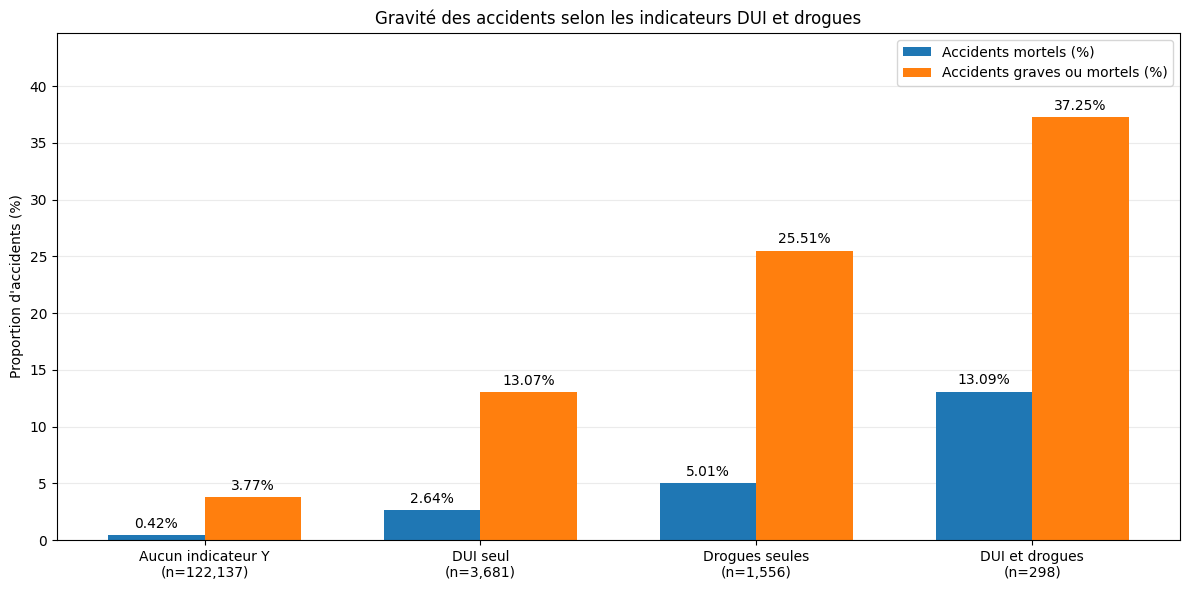

In [78]:
import matplotlib.pyplot as plt
import numpy as np

# Seulement 4 lignes à récupérer depuis Spark
donnees = stats_exclusives.toPandas()

ordre = [
    "Aucun indicateur Y",
    "DUI seul",
    "Drogues seules",
    "DUI et drogues"
]

donnees = donnees.set_index("Groupe").loc[ordre]

labels = [
    f"{groupe}\n(n={int(donnees.loc[groupe, 'Accidents']):,})"
    for groupe in ordre
]

x = np.arange(len(ordre))
largeur = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

barres1 = ax.bar(
    x - largeur / 2,
    donnees["% mortels"],
    largeur,
    label="Accidents mortels (%)"
)

barres2 = ax.bar(
    x + largeur / 2,
    donnees["% graves ou mortels"],
    largeur,
    label="Accidents graves ou mortels (%)"
)

ax.bar_label(barres1, fmt="%.2f%%", padding=3)
ax.bar_label(barres2, fmt="%.2f%%", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Proportion d'accidents (%)")
ax.set_title(
    "Gravité des accidents selon les indicateurs DUI et drogues"
)
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.set_ylim(
    0,
    donnees["% graves ou mortels"].max() * 1.2
)

plt.tight_layout()
plt.show()

### 8.5. Bilan de l'analyse

En séparant les accidents en quatre catégories exclusives, j'ai pu comparer leurs niveaux de gravité sans compter plusieurs fois les mêmes enregistrements.

Je constate que la proportion d'accidents graves ou mortels atteint 37,25 % lorsque les deux indicateurs sont signalés, contre 13,07 % pour le DUI seul et 25,51 % pour les drogues seules.

Pour les accidents sans indicateur `Y` enregistré, cette proportion est de 3,77 %.

Ces différences sont importantes, mais je dois rester prudent dans leur interprétation. Le groupe DUI et drogues ne contient que 298 accidents, alors que le groupe sans indicateur en contient 122 137. Les estimations n'ont donc pas la même précision statistique.

De plus, les valeurs NULL ne permettent pas de confirmer l'absence d'alcool ou de drogues.

Cette amélioration permet de rendre les résultats plus faciles à comparer, tout en évitant les chevauchements présents dans l'analyse initiale.

## 9. Comparaison finale des trois approches

### 9.1. Vérification de la cohérence des requêtes

Dans la dernière partie de l'article, j'ai remarqué que les filtres et les opérations d'agrégation utilisés ne correspondaient pas toujours exactement à la question étudiée.

J'ai donc choisi de reprendre l'analyse des accidents impliquant au moins une unité associée à un permis `Unlicenced`.

Je conserve la correction effectuée précédemment pour éviter de compter plusieurs fois les victimes d'un même accident.

Mon objectif est de reproduire cette analyse avec les DataFrames, Spark SQL et les RDD, puis de vérifier que les trois approches produisent des résultats identiques.

In [79]:
# Requête SQL sans duplication des accidents
victimes_sql = spark.sql("""
    SELECT
        c.Suburb,
        SUM(c.`Total Cas`) AS `Victimes corrigees`
    FROM crash c
    WHERE EXISTS (
        SELECT 1
        FROM units u
        WHERE u.REPORT_ID = c.REPORT_ID
          AND u.`Licence Type` = 'Unlicenced'
    )
    GROUP BY c.Suburb
""")

victimes_sql.orderBy(
    F.desc("Victimes corrigees")
).show(20, truncate=False)

# Comparaison avec la version DataFrame corrigée
difference_sql = victimes_sql.exceptAll(
    victimes_corrigees
).count()

difference_df = victimes_corrigees.exceptAll(
    victimes_sql
).count()

print("Différences SQL :", difference_sql)
print("Différences DataFrame :", difference_df)

assert difference_sql == 0
assert difference_df == 0

print("SQL et DataFrame identiques : OK")

+---------------+------------------+
|Suburb         |Victimes corrigees|
+---------------+------------------+
|ADELAIDE       |42                |
|SALISBURY      |30                |
|PROSPECT       |27                |
|INGLE FARM     |22                |
|MORPHETT VALE  |20                |
|SALISBURY EAST |19                |
|MURRAY BRIDGE  |19                |
|DRY CREEK      |19                |
|NORTH ADELAIDE |17                |
|MAWSON LAKES   |17                |
|ENFIELD        |16                |
|SALISBURY DOWNS|15                |
|GEPPS CROSS    |15                |
|REGENCY PARK   |15                |
|PARA HILLS WEST|14                |
|ELIZABETH PARK |14                |
|SEATON         |14                |
|BEDFORD PARK   |13                |
|DAVOREN PARK   |13                |
|MOUNT GAMBIER  |13                |
+---------------+------------------+
only showing top 20 rows

Différences SQL : 0
Différences DataFrame : 0
SQL et DataFrame identiques : OK


### 9.2. Reproduction avec les RDD

Après avoir obtenu les mêmes résultats avec les DataFrames et Spark SQL, je vais réaliser la dernière analyse avec les RDD.

Je commence par récupérer les identifiants des accidents associés à au moins une unité dont le permis est renseigné comme `Unlicenced`.

J'utilise ensuite `distinct()` pour éviter de conserver plusieurs fois le même identifiant, puis une jointure RDD pour retrouver les accidents concernés.

Enfin, j'utilise `reduceByKey()` pour calculer le nombre total de victimes par quartier.

Je prends également en compte les valeurs NULL lors du calcul pour conserver le même comportement que la fonction SQL `SUM()`.

In [80]:
from pyspark.sql.types import (
    StructType, StructField, StringType, LongType
)
from pyspark.sql import functions as F

# 1. Identifiants distincts des accidents avec
# au moins une unité "Unlicenced"
ids_rdd = (
    units_rdd
    .filter(
        lambda row:
        row["REPORT_ID"] is not None
        and row["Licence Type"] == "Unlicenced"
    )
    .map(lambda row: row["REPORT_ID"])
    .distinct()
    .map(lambda identifiant: (identifiant, 1))
)

# 2. Indexer les accidents par REPORT_ID
crash_index_rdd = (
    crash_rdd
    .filter(lambda row: row["REPORT_ID"] is not None)
    .map(lambda row: (row["REPORT_ID"], row))
)

# 3. Jointure sans duplication due aux Units
accidents_rdd = crash_index_rdd.join(ids_rdd)

# 4. Préparer la somme des victimes
# (somme, nombre de valeurs non NULL)
victimes_rdd = accidents_rdd.map(
    lambda element: (
        element[1][0]["Suburb"],
        (
            element[1][0]["Total Cas"]
            if element[1][0]["Total Cas"] is not None
            else 0,
            int(element[1][0]["Total Cas"] is not None)
        )
    )
)

# 5. Agrégation par quartier
victimes_rdd = (
    victimes_rdd
    .reduceByKey(
        lambda a, b: (
            a[0] + b[0],
            a[1] + b[1]
        )
    )
    .map(
        lambda x: (
            x[0],
            int(x[1][0]) if x[1][1] > 0 else None
        )
    )
)

# 6. Conversion en DataFrame pour comparer
schema = StructType([
    StructField("Suburb", StringType(), True),
    StructField("Victimes corrigees", LongType(), True)
])

victimes_rdd_df = spark.createDataFrame(
    victimes_rdd,
    schema=schema
)

victimes_rdd_df.orderBy(
    F.desc("Victimes corrigees")
).show(20, truncate=False)

print(
    "Total des victimes :",
    victimes_rdd_df.agg(
        F.sum("Victimes corrigees")
    ).first()[0]
)

+---------------+------------------+
|Suburb         |Victimes corrigees|
+---------------+------------------+
|ADELAIDE       |42                |
|SALISBURY      |30                |
|PROSPECT       |27                |
|INGLE FARM     |22                |
|MORPHETT VALE  |20                |
|SALISBURY EAST |19                |
|DRY CREEK      |19                |
|MURRAY BRIDGE  |19                |
|NORTH ADELAIDE |17                |
|MAWSON LAKES   |17                |
|ENFIELD        |16                |
|SALISBURY DOWNS|15                |
|REGENCY PARK   |15                |
|GEPPS CROSS    |15                |
|PARA HILLS WEST|14                |
|ELIZABETH PARK |14                |
|SEATON         |14                |
|MOUNT GAMBIER  |13                |
|DAVOREN PARK   |13                |
|BEDFORD PARK   |13                |
+---------------+------------------+
only showing top 20 rows

Total des victimes : 2053


In [81]:
# Comparer les résultats RDD, DataFrame et SQL

diff_rdd_df = victimes_rdd_df.exceptAll(
    victimes_corrigees
).count()

diff_df_rdd = victimes_corrigees.exceptAll(
    victimes_rdd_df
).count()

diff_rdd_sql = victimes_rdd_df.exceptAll(
    victimes_sql
).count()

diff_sql_rdd = victimes_sql.exceptAll(
    victimes_rdd_df
).count()

print("RDD vers DataFrame :", diff_rdd_df)
print("DataFrame vers RDD :", diff_df_rdd)
print("RDD vers SQL :", diff_rdd_sql)
print("SQL vers RDD :", diff_sql_rdd)

assert all(x == 0 for x in [
    diff_rdd_df,
    diff_df_rdd,
    diff_rdd_sql,
    diff_sql_rdd
])

print("\nRDD = DataFrame = Spark SQL : OK")

RDD vers DataFrame : 0
DataFrame vers RDD : 0
RDD vers SQL : 0
SQL vers RDD : 0

RDD = DataFrame = Spark SQL : OK


### 9.3. Synthèse des améliorations apportées

Au cours de ce TP, j'ai commencé par reproduire les analyses de l'article, puis j'ai cherché à identifier les limites des traitements proposés.

J'ai notamment apporté plusieurs améliorations :

- **Partitionnement des données :** j'ai séparé les immatriculations inconnues des immatriculations renseignées. Le partitionnement initial regroupait 47 463 valeurs inconnues avec les autres immatriculations.

- **Traitement des âges :** j'ai nettoyé les valeurs avant de calculer les moyennes et utilisé `reduceByKey()` pour éviter de regrouper tous les âges dans des listes.

- **Filtrage des quartiers :** j'ai utilisé `upper()` et `trim()` pour rendre les recherches moins sensibles aux différences de saisie.

- **Classement des accidents :** j'ai ajouté des critères de tri et conservé les ex æquo. Cela m'a permis d'identifier 11 accidents atteignant le seuil du top 10, au lieu d'en retenir arbitrairement 10.

- **Analyse de la mortalité :** j'ai complété le nombre total de décès par la proportion d'accidents mortels pour chaque type d'accident.

- **Correction des jointures :** j'ai utilisé `left_semi` pour éviter de compter plusieurs fois les victimes d'un même accident. Le total est passé de 2 072 à 2 053, ce qui correspond à 19 occurrences comptées en trop dans la première version.

- **Vérification des approches PySpark :** j'ai utilisé `exceptAll()` pour vérifier que les traitements RDD, DataFrame et Spark SQL produisaient exactement les mêmes résultats, y compris en présence de doublons.

- **Comparaison des performances :** j'ai complété les mesures avec `count()` par un second benchmark utilisant `collect()`, après avoir constaté que Spark pouvait simplifier les opérations lors du comptage.

- **Analyse de l'alcool et des drogues :** j'ai créé quatre catégories exclusives afin d'éviter les chevauchements et de comparer correctement les proportions d'accidents graves ou mortels.

Ces modifications ne visent pas toutes à améliorer la vitesse d'exécution. Certaines permettent surtout d'éviter des erreurs statistiques, de rendre les résultats plus fiables ou de faciliter leur interprétation.

J'ai conservé les traitements originaux lorsqu'ils étaient nécessaires pour mesurer les différences avant et après les corrections.

## 10. Conclusion générale

Ce TP m'a permis de découvrir et de comparer plusieurs façons d'analyser des données avec PySpark, en utilisant les RDD, les DataFrames et Spark SQL.

J'ai travaillé sur les données d'accidents de la route en Australie-Méridionale entre 2012 et 2019, avec 127 672 accidents et 272 591 enregistrements dans le jeu de données Units.

J'ai commencé par reproduire les traitements présentés dans l'article de référence, notamment le partitionnement, l'analyse des âges, le classement des accidents, l'étude de leur gravité et les jointures entre les différents fichiers.

Au fur et à mesure, j'ai identifié plusieurs limites dans certaines requêtes. La plus importante concernait le double comptage des victimes après une jointure, qui entraînait une surestimation de 19 occurrences. J'ai pu corriger ce problème et vérifier que les trois approches PySpark retrouvaient les mêmes résultats.

J'ai également comparé les performances des RDD, DataFrames et Spark SQL. Dans mes tests sur Google Colab, les DataFrames et Spark SQL ont obtenu des temps relativement proches, tandis que les RDD étaient généralement plus lents.

L'analyse des plans d'exécution m'a permis de mieux comprendre certaines optimisations réalisées automatiquement par Spark, comme la sélection des colonnes nécessaires et l'utilisation d'une jointure `BroadcastHashJoin`.

Ce TP m'a surtout montré que la qualité d'une analyse Big Data ne dépend pas uniquement de la rapidité du traitement. La façon de nettoyer les données, de réaliser les jointures, de choisir les indicateurs et de vérifier les résultats joue également un rôle essentiel.

Pour aller plus loin, il serait intéressant de reproduire ces expériences sur un volume de données plus important et sur un environnement Spark distribué, afin d'étudier plus précisément l'effet du partitionnement et du parallélisme sur les performances.